# MonReader — page-flip detection

**Goal:** predict `notflip = 0` or `flip = 1` from a single image. **Primary metric:** F1 for class 1. A separate extension detects whether a sequence contains a flip.

In [1]:
# Run once if dependencies are missing, then restart the kernel.
# %pip install tensorflow pandas numpy scikit-learn matplotlib pillow

In [2]:
from pathlib import Path
import re, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (f1_score, precision_score, recall_score,
    accuracy_score, classification_report, ConfusionMatrixDisplay)
from IPython.display import display

SEED = 42
keras.utils.set_random_seed(SEED)
print("Python:", platform.python_version(), "TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

Python: 3.13.9 TensorFlow: 2.21.0
GPUs: []


## Configuration
Set the directory containing the extracted image folders, e.g. `images/training/flip` and `images/testing/notflip`. The scanner searches recursively. Class folder names are normalized to recognize flip/flipping and notflip/notflipping.

The default preserves a supplied test folder and creates a grouped validation split from training. If original videos overlap across supplied splits, the notebook stops. Only after checking the dataset, set `PRESERVE_OFFICIAL_TEST=False` to create a new video-disjoint split; clearly report this change.

**Video IDs must identify original source videos.** If IDs reset between folders, or separate clip IDs come from the same original recording, edit `parse_filename` / use an original-video mapping before training.

In [3]:
PROJECT_DIR = Path.cwd()  # Get the notebook's current working folder.

print("Working folder:", PROJECT_DIR)  # Display the folder Python is using.
DATA_DIR = PROJECT_DIR / "data1"  # Point to the data folder inside your project.

print("Data folder:", DATA_DIR)  # Display the dataset location.
print("Folder exists:", DATA_DIR.is_dir())  # Check whether the folder exists.

#DATA_DIR = Path(r"C:\Users\YourName\Documents\MonReader_Project\data")  # CHANGE THIS
OUT = Path("monreader_outputs")
OUT.mkdir(exist_ok=True)
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
BASELINE_EPOCHS = 15
HEAD_EPOCHS = 8
FINE_TUNE_EPOCHS = 5
PRESERVE_OFFICIAL_TEST = False
RUN_TRANSFER = True
CLASS_NAMES = ["notflip", "flip"]
assert DATA_DIR.is_dir(), f"Dataset folder does not exist: {DATA_DIR}"

Working folder: C:\Users\anagha\Apziva\ApzivaP4_MonReader
Data folder: C:\Users\anagha\Apziva\ApzivaP4_MonReader\data1
Folder exists: True


##  Build and validate the image table
Filenames should end with `VideoID_FrameNumber`, e.g. `12_0042.jpg`. Unrecognized files stop the pipeline so they cannot silently receive incorrect groups. Corrupt images are listed and excluded. Exact decoded-pixel duplicates are identified; conflicting labels stop execution.

In [4]:
def parse_filename(path):
    match = re.fullmatch(r"(.+)_([0-9]+)", path.stem)
    if not match:
        raise ValueError(f"Expected VideoID_FrameNumber: {path.name}")
    return match.group(1), int(match.group(2))

def normalized(text):
    return re.sub(r"[^a-z0-9]", "", text.lower())

aliases = {"flip": 1, "flipping": 1, "notflip": 0, "notflipping": 0}
rows, corrupt, unknown = [], [], []
for path in sorted(DATA_DIR.rglob("*")):
    if path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp"}:
        continue
    parts = [normalized(p) for p in path.relative_to(DATA_DIR).parts[:-1]]
    labels = {aliases[p] for p in parts if p in aliases}
    if len(labels) != 1:
        unknown.append(str(path)); continue
    video_id, frame = parse_filename(path)
    folder_split = "test" if any(p in {"test", "testing"} for p in parts) else "train"
    try:
        with Image.open(path) as image:
            rgb = image.convert("RGB")
            width, height = rgb.size
            digest = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
    except Exception as exc:
        corrupt.append({"path": str(path), "error": str(exc)}); continue
    rows.append(dict(path=str(path), label=labels.pop(), video_id=video_id,
                     frame=frame, official_split=folder_split, width=width,
                     height=height, pixel_hash=digest))
assert not unknown, f"Unrecognized class folders; examples: {unknown[:5]}"
assert rows, "No readable labeled images found. Check DATA_DIR."
images = pd.DataFrame(rows)
display(pd.DataFrame(corrupt))
conflicts = images.groupby("pixel_hash").label.nunique()
assert not (conflicts > 1).any(), "Identical image pixels have conflicting labels; review labels."
print("Readable images:", len(images), "Duplicate copies:", images.pixel_hash.duplicated().sum())
display(images.head())
display(pd.crosstab(images.official_split, images.label))
display(images[["width", "height"]].describe())
print("Unique video IDs:", images.video_id.nunique())

""


Readable images: 2989 Duplicate copies: 0


,path,label,video_id,frame,official_split,width,height,pixel_hash
0,C:\Users\anagha\Apziva\ApzivaP4_MonReader\data...,1,0001,20,test,1080,1920,476aff9942fa0152970503402305b0bf1de18e689aafb1...
1,C:\Users\anagha\Apziva\ApzivaP4_MonReader\data...,1,0002,12,test,1080,1920,75c2e51e5a24b7434ce0f3c96ae25545dcb6ee3f07d8dc...
2,C:\Users\anagha\Apziva\ApzivaP4_MonReader\data...,1,0002,13,test,1080,1920,9457ca21a3cdcd8c454e9cab98c0c93e21c4e05d49ebe0...
3,C:\Users\anagha\Apziva\ApzivaP4_MonReader\data...,1,0002,15,test,1080,1920,5854aee6c3385b75098e1f064b470eccdc7c6cd5361c09...
4,C:\Users\anagha\Apziva\ApzivaP4_MonReader\data...,1,0002,17,test,1080,1920,e66dcd0cfa1984f68d14ace71ec4e4537e977da6d0ee00...


label,0,1
official_split,,
test,307,290
train,1230,1162


,width,height
count,2989.0,2989.0
mean,1080.0,1920.0
std,0.0,0.0
min,1080.0,1920.0
25%,1080.0,1920.0
50%,1080.0,1920.0
75%,1080.0,1920.0
max,1080.0,1920.0


Unique video IDs: 65


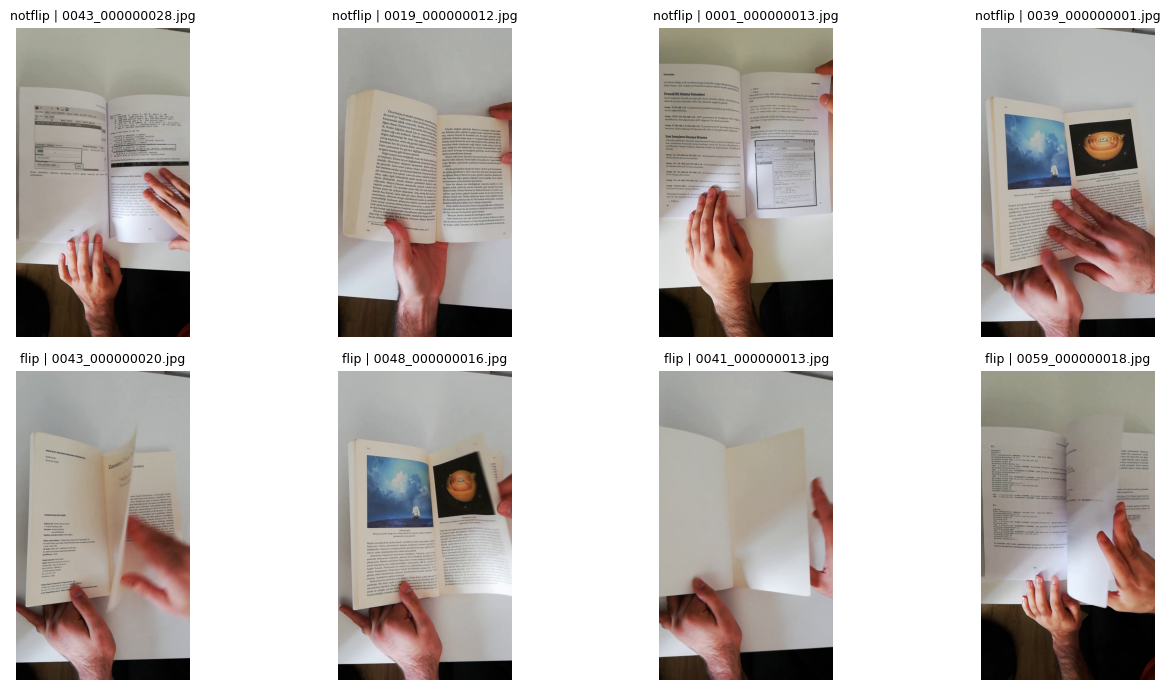

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for label in [0, 1]:
    sample = images[images.label == label].sample(n=min(4, sum(images.label == label)), random_state=SEED)
    for ax in axes[label]: ax.axis("off")
    for ax, row in zip(axes[label], sample.itertuples()):
        with Image.open(row.path) as img: ax.imshow(img.convert("RGB"))
        ax.set_title(f"{CLASS_NAMES[label]} | {Path(row.path).name}", fontsize=9)
plt.tight_layout(); plt.show()

##  Split by video and audit leakage
Adjacent frames from one recording must not occur in both training and evaluation. Split selection below uses only group membership and class balance, never model performance. Aim for approximately 60/20/20 when no official test split is retained. Actual sizes depend on video lengths.

Exact duplicates across partitions cause a stop. Inspect their origin and correct the grouping, rather than silently allowing leakage. Visual near-duplicates still require manual review.

In [6]:
def grouped_split(df, fraction, seed=SEED):
    # Pick a reasonably balanced split among group-only candidates.
    if df.video_id.nunique() < 3:
        raise ValueError("Too few independent videos for a reliable split.")
    candidates = []
    splitter = GroupShuffleSplit(n_splits=100, test_size=fraction, random_state=seed)
    for a, b in splitter.split(df, df.label, groups=df.video_id):
        left, right = df.iloc[a], df.iloc[b]
        if left.label.nunique() == 2 and right.label.nunique() == 2:
            score = abs(len(right)/len(df)-fraction) + abs(right.label.mean()-df.label.mean())
            candidates.append((score, a, b))
    if not candidates:
        raise ValueError("Cannot obtain both classes in each group split. Review video IDs.")
    _, a, b = min(candidates, key=lambda item: item[0])
    return df.iloc[a].copy(), df.iloc[b].copy()

if PRESERVE_OFFICIAL_TEST and (images.official_split == "test").any():
    pool = images[images.official_split == "train"].copy()
    test_df = images[images.official_split == "test"].copy()
    overlap = set(pool.video_id) & set(test_df.video_id)
    assert not overlap, f"Source video IDs overlap supplied train/test: {sorted(overlap)[:10]}"
else:
    pool, test_df = grouped_split(images, 0.20)
train_df, val_df = grouped_split(pool, 0.25)

for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert not (set(a.video_id) & set(b.video_id)), "Video leakage"
    assert not (set(a.pixel_hash) & set(b.pixel_hash)), "Exact duplicate leakage: review source grouping"
# Keep original frame rows for sequences; remove duplicates only for image training/evaluation.
sequence_val_df, sequence_test_df = val_df.copy(), test_df.copy()
train_df, val_df, test_df = [d.drop_duplicates("pixel_hash").reset_index(drop=True)
                            for d in (train_df, val_df, test_df)]
for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    assert df.label.nunique() == 2, f"{name} needs both classes"
    df.to_csv(OUT / f"{name}_manifest.csv", index=False)
    print(name, "images:", len(df), "videos:", df.video_id.nunique(), "flip fraction:", round(df.label.mean(), 3))

train images: 1798 videos: 39 flip fraction: 0.484
validation images: 601 videos: 13 flip fraction: 0.488
test images: 590 videos: 13 flip fraction: 0.488


##  Input pipeline
All models receive RGB pixels in `[0,255]`. Normalization is included inside each model: CNN scales to `[0,1]`, MobileNetV2 to `[-1,1]`, and EfficientNetB0 uses its built-in preprocessing. Do not divide EfficientNet input by 255 again.

Augmentation runs during training only. Evaluation order stays fixed so probabilities match table rows.

In [7]:
def load_image(path):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    return tf.image.resize(tf.cast(image, tf.float32), IMAGE_SIZE)

def make_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((df.path.to_numpy(), df.label.to_numpy(dtype="float32")))
    if training: ds = ds.shuffle(len(df), seed=SEED)
    ds = ds.map(lambda p, y: (load_image(p), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

def augmentation():
    return keras.Sequential([
        layers.RandomRotation(0.03, fill_mode="reflect"),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10),
    ], name="augmentation")

counts = train_df.label.value_counts()
class_weight = {int(c): len(train_df)/(2*int(count)) for c, count in counts.items()}
print("Training class weights:", class_weight)

Training class weights: {0: 0.9697950377562028, 1: 1.032146957520092}


##  Train a CNN baseline and transfer-learning models
Early stopping restores the epoch with the lowest validation loss. Model and threshold selection then use validation F1. Fine-tuning uses a smaller learning rate and keeps batch-normalization layers frozen. Both frozen and fine-tuned checkpoints are compared, so a worse fine-tuned model will not overwrite a better candidate.

In [8]:
def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[keras.metrics.BinaryAccuracy(name="accuracy")])

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.5)]

histories, candidates = {}, []

def fit_candidate(model, name, epochs, lr):
    compile_model(model, lr)
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                        class_weight=class_weight, callbacks=callbacks(), verbose=1)
    path = OUT / f"{name}.keras"
    model.save(path)
    histories[name] = history.history
    candidates.append({"model": name, "path": str(path)})
    return history

inputs = keras.Input(shape=(*IMAGE_SIZE, 3))
x = layers.Rescaling(1./255)(augmentation()(inputs))
for filters in [32, 64, 128]:
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
cnn = keras.Model(inputs, outputs, name="baseline_cnn")
cnn.summary()
fit_candidate(cnn, "cnn", BASELINE_EPOCHS, 1e-3)

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,377 (364.75 KB)

 Trainable params: 93,377 (364.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


C:\Users\anagha\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


113/113 ━━━━━━━━━━━━━━━━━━━━ 38s 240ms/step - accuracy: 0.5128 - loss: 0.6947 - val_accuracy: 0.5507 - val_loss: 0.6931 - learning_rate: 0.0010
Epoch 2/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 28s 243ms/step - accuracy: 0.4944 - loss: 0.6931 - val_accuracy: 0.4875 - val_loss: 0.6928 - learning_rate: 0.0010
Epoch 3/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 27s 235ms/step - accuracy: 0.5189 - loss: 0.6919 - val_accuracy: 0.5125 - val_loss: 0.6935 - learning_rate: 0.0010
Epoch 4/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 27s 240ms/step - accuracy: 0.5350 - loss: 0.6895 - val_accuracy: 0.4842 - val_loss: 0.6903 - learning_rate: 0.0010
Epoch 5/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 27s 237ms/step - accuracy: 0.5534 - loss: 0.6835 - val_accuracy: 0.6106 - val_loss: 0.6831 - learning_rate: 0.0010
Epoch 6/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 27s 242ms/step - accuracy: 0.5712 - loss: 0.6764 - val_accuracy: 0.4742 - val_loss: 0.6796 - learning_rate: 0.0010
Epoch 7/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 25s 222ms/step - accuracy: 0.5962 - loss:

In [9]:
def build_transfer(kind):
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3))
    x = augmentation()(inputs)
    if kind == "mobilenetv2":
        x = layers.Rescaling(1./127.5, offset=-1)(x)
        base = keras.applications.MobileNetV2(include_top=False, weights="imagenet",
                                             input_shape=(*IMAGE_SIZE, 3))
    else:
        base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                                input_shape=(*IMAGE_SIZE, 3))
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name=kind), base

if RUN_TRANSFER:
    for kind in ["mobilenetv2", "efficientnetb0"]:
        keras.backend.clear_session()
        model, base = build_transfer(kind)
        fit_candidate(model, kind + "_frozen", HEAD_EPOCHS, 1e-3)
        base.trainable = True
        for layer in base.layers[:-30]: layer.trainable = False
        for layer in base.layers:
            if isinstance(layer, layers.BatchNormalization): layer.trainable = False
        fit_candidate(model, kind + "_finetuned", FINE_TUNE_EPOCHS, 1e-5)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 21s 154ms/step - accuracy: 0.6930 - loss: 0.5755 - val_accuracy: 0.6872 - val_loss: 0.5748 - learning_rate: 0.0010
Epoch 2/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 17s 146ms/step - accuracy: 0.8220 - loss: 0.4090 - val_accuracy: 0.7388 - val_loss: 0.5400 - learning_rate: 0.0010
Epoch 3/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 17s 145ms/step - accuracy: 0.8654 - loss: 0.3447 - val_accuracy: 0.7687 - val_loss: 0.5128 - learning_rate: 0.0010
Epoch 4/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 17s 145ms/step - accuracy: 0.8737 - loss: 0.3113 - val_accuracy: 0.7820 - val_loss: 0.5073 - learning_rate: 0.0010
Epoch 5/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 17s 145ms/step - accuracy: 0.8915 - loss: 0.2864 - val_accuracy: 0.7870 - val_loss: 0.4939 - learning_rate: 0.0010
Epoch 6/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 17s 145ms/step - accuracy: 0.9077 - loss: 0.2423 - val_accuracy: 0.7920 - val_loss: 0.5297 - learning_rate: 0.0010
Epoch 7/8
113/113 ━━━━━━━━

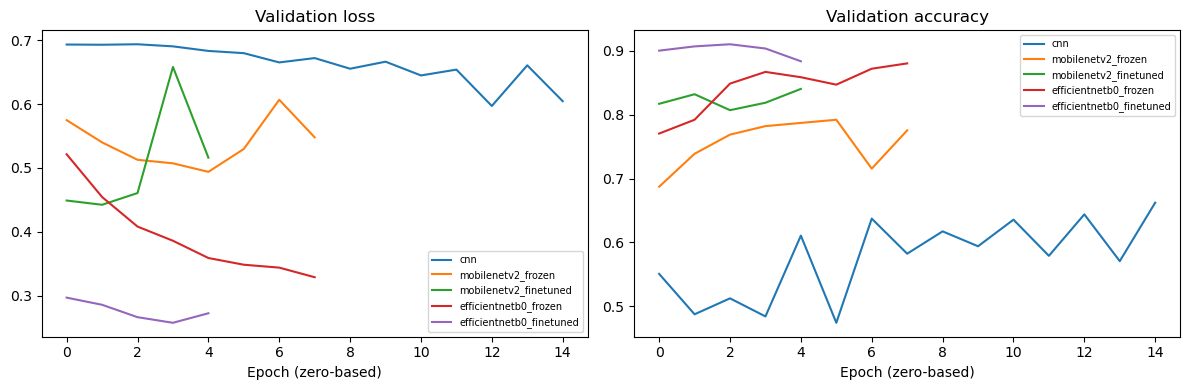

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    axes[0].plot(h["val_loss"], label=name)
    axes[1].plot(h["val_accuracy"], label=name)
axes[0].set_title("Validation loss"); axes[1].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Epoch (zero-based)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Select model and threshold using validation F1
A sigmoid probability is converted to `flip` when it is at least the threshold. The default is 0.5; the best validation threshold may differ. Repeated validation tuning can overfit, so keep the test set untouched until the final choice.

In [11]:
thresholds = np.linspace(0.05, 0.95, 91)
comparison = []
for candidate in candidates:
    model = keras.models.load_model(candidate["path"])
    p = model.predict(val_ds, verbose=0).ravel()
    scores = np.array([f1_score(val_df.label, p >= t, zero_division=0) for t in thresholds])
    # Break F1 ties by preferring the threshold closest to 0.5.
    tied = np.flatnonzero(np.isclose(scores, scores.max()))
    i = min(tied, key=lambda j: abs(thresholds[j] - 0.5))
    comparison.append({**candidate, "threshold": float(thresholds[i]),
                       "validation_f1": float(scores[i]),
                       "validation_f1_at_0.5": f1_score(val_df.label, p >= 0.5),
                       "file_mb": Path(candidate["path"]).stat().st_size/1e6})
comparison = pd.DataFrame(comparison).sort_values(
    ["validation_f1", "file_mb"], ascending=[False, True]).reset_index(drop=True)
display(comparison)
comparison.to_csv(OUT / "validation_comparison.csv", index=False)
best = comparison.iloc[0]
best_model = keras.models.load_model(best["path"])
BEST_THRESHOLD = float(best.threshold)
print("Selected:", best.model, "Threshold:", BEST_THRESHOLD)

,model,path,threshold,validation_f1,validation_f1_at_0.5,file_mb
0,efficientnetb0_finetuned,monreader_outputs\efficientnetb0_finetuned.keras,0.52,0.910653,0.901695,28.953775
1,efficientnetb0_frozen,monreader_outputs\efficientnetb0_frozen.keras,0.41,0.892308,0.870504,17.076805
2,mobilenetv2_finetuned,monreader_outputs\mobilenetv2_finetuned.keras,0.35,0.835484,0.831386,21.747549
3,mobilenetv2_frozen,monreader_outputs\mobilenetv2_frozen.keras,0.40,0.790541,0.773852,9.654527
4,cnn,monreader_outputs\cnn.keras,0.31,0.759945,0.513636,1.180012


Selected: efficientnetb0_finetuned Threshold: 0.5199999999999999


## Final single-image evaluation
F1 balances precision (how many predicted flips are real) and recall (how many actual flips are found). Report both classes as well as the primary flipping F1. The test result must not be used to select another threshold or model.

              precision    recall  f1-score   support

     notflip       0.92      0.94      0.93       302
        flip       0.94      0.91      0.93       288

    accuracy                           0.93       590
   macro avg       0.93      0.93      0.93       590
weighted avg       0.93      0.93      0.93       590



,flip_f1,flip_precision,flip_recall,accuracy
0,0.926056,0.939286,0.913194,0.928814


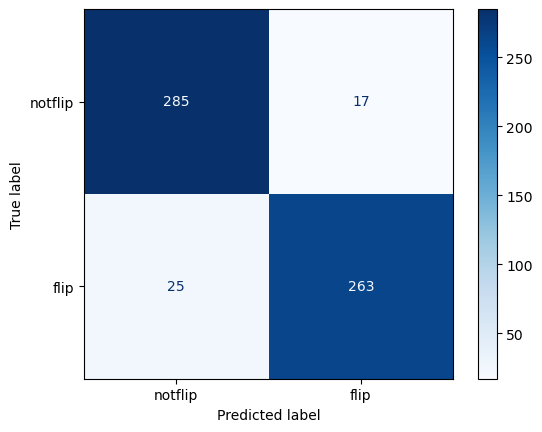

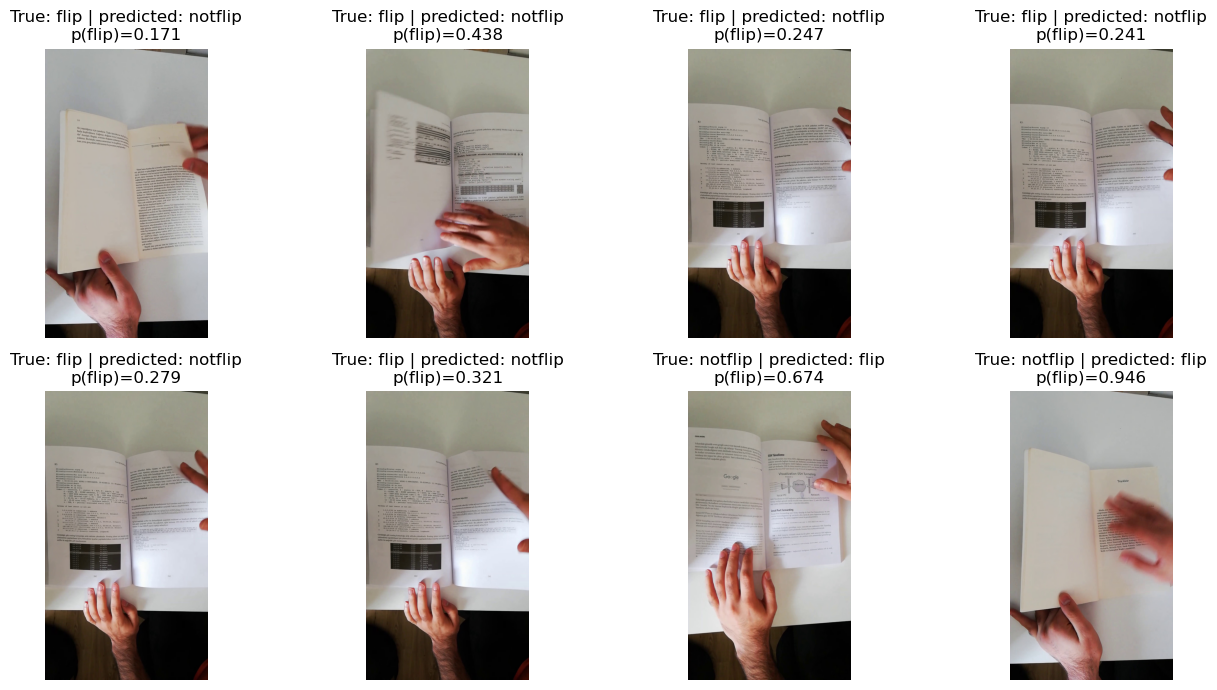

In [19]:
test_p = best_model.predict(test_ds, verbose=0).ravel()
test_pred = (test_p >= BEST_THRESHOLD).astype(int)
print(classification_report(test_df.label, test_pred, labels=[0, 1], target_names=CLASS_NAMES, zero_division=0))
metrics = {"flip_f1": f1_score(test_df.label, test_pred, zero_division=0),
           "flip_precision": precision_score(test_df.label, test_pred, zero_division=0),
           "flip_recall": recall_score(test_df.label, test_pred, zero_division=0),
           "accuracy": accuracy_score(test_df.label, test_pred)}
display(pd.DataFrame([metrics]))
ConfusionMatrixDisplay.from_predictions(test_df.label, test_pred, labels=[0, 1], display_labels=CLASS_NAMES, cmap="Blues")
plt.show()
test_results = test_df.assign(probability_flip=test_p, prediction=test_pred)
test_results.to_csv(OUT / "test_predictions.csv", index=False)
(OUT / "test_metrics.json").write_text(json.dumps(metrics, indent=2))

errors = test_results[test_results.label != test_results.prediction].head(8)
if errors.empty:
    print("No misclassified test images.")
else:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax in axes.flat: ax.axis("off")
    for ax, row in zip(axes.flat, errors.itertuples()):
        with Image.open(row.path) as img: ax.imshow(img.convert("RGB"))
        ax.set_title(f"True: {CLASS_NAMES[row.label]} | predicted: {CLASS_NAMES[row.prediction]}\np(flip)={row.probability_flip:.3f}")
    plt.tight_layout(); plt.show()

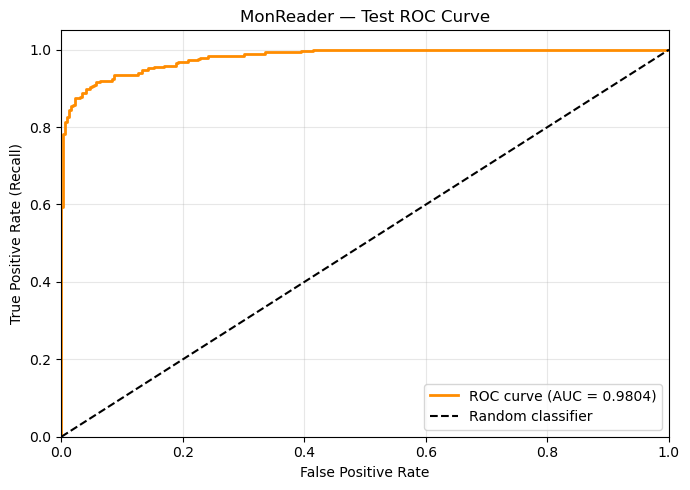

,flip_f1,flip_precision,flip_recall,accuracy,roc_auc
0,0.926056,0.939286,0.913194,0.928814,0.980408


In [20]:
from sklearn.metrics import roc_curve, roc_auc_score

# Use probabilities, not thresholded predictions.
fpr, tpr, thresholds = roc_curve(test_df.label, test_p)
roc_auc = roc_auc_score(test_df.label, test_p)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr, tpr,
    color="darkorange",
    linewidth=2,
    label=f"ROC curve (AUC = {roc_auc:.4f})"
)
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("MonReader — Test ROC Curve")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "test_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# Add ROC-AUC to the saved test metrics.
metrics["roc_auc"] = float(roc_auc)
(OUT / "test_metrics.json").write_text(json.dumps(metrics, indent=2))
display(pd.DataFrame([metrics]))

## Save the chosen model and predict a new image
The saved model includes normalization. Reload it with its matching JSON threshold. Input is an RGB image resized to 224×224, with pixel values in `[0,255]`.

In [16]:
best_model.save(OUT / "best_model.keras")
config = {"model_name": str(best.model), "threshold": BEST_THRESHOLD,
          "image_size": list(IMAGE_SIZE), "class_names": CLASS_NAMES,
          "input_range": [0, 255], "tensorflow_version": tf.__version__, "seed": SEED}
(OUT / "inference_config.json").write_text(json.dumps(config, indent=2))

def predict_image(path, model=best_model, threshold=BEST_THRESHOLD):
    image = load_image(str(path))
    probability = float(model.predict(tf.expand_dims(image, 0), verbose=0)[0, 0])
    return {"label": CLASS_NAMES[int(probability >= threshold)], "probability_flip": probability}

# Example: replace this with a new image path when available.
display(predict_image(test_df.path.iloc[0]))
print("Saved outputs to:", OUT.resolve())

{'label': 'flip', 'probability_flip': 0.5234504342079163}

Saved outputs to: C:\Users\anagha\Apziva\ApzivaP4_MonReader\monreader_outputs


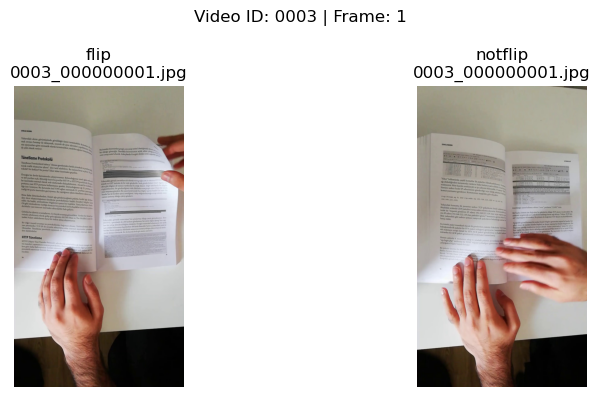

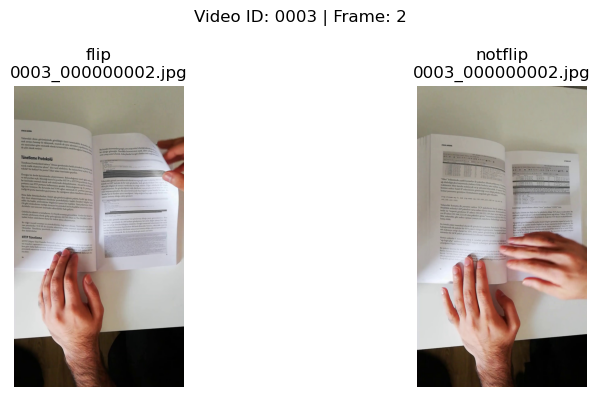

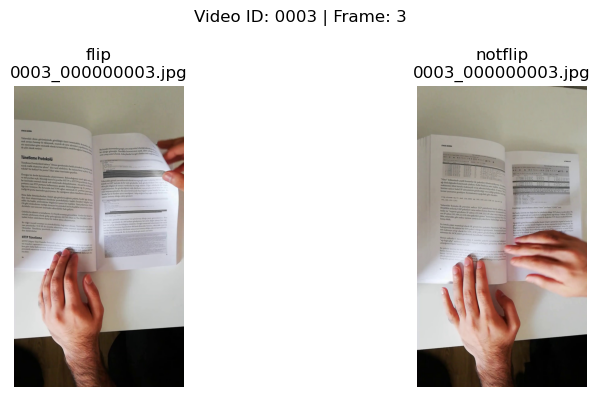

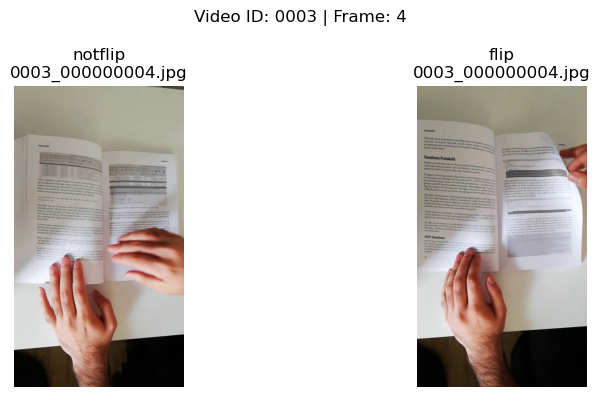

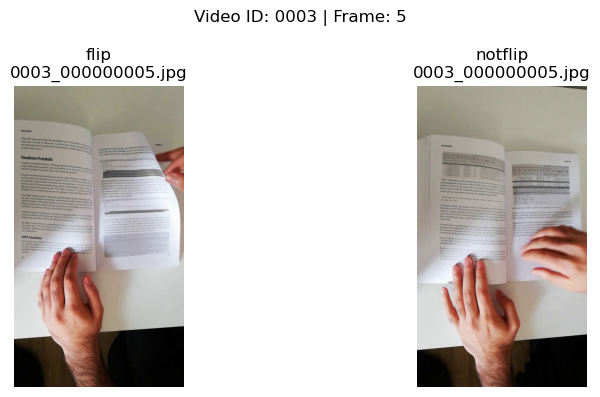

In [17]:
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

# Find images sharing the same video ID and frame number.
duplicates = sequence_val_df[
    sequence_val_df.duplicated(["video_id", "frame"], keep=False)
]

# Show the first 5 repeated combinations.
groups = list(duplicates.groupby(["video_id", "frame"]))[:5]

for (video_id, frame), group in groups:
    fig, axes = plt.subplots(
        1, len(group),
        figsize=(5 * len(group), 4),
        squeeze=False
    )

    for ax, row in zip(axes[0], group.itertuples()):
        with Image.open(row.path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"{CLASS_NAMES[row.label]}\n"
            f"{Path(row.path).name}"
        )
        ax.axis("off")

    fig.suptitle(f"Video ID: {video_id} | Frame: {frame}")
    plt.tight_layout()
    plt.show()